# 🛍️ Mall Customer Segmentation: Comprehensive Exploratory Data Analysis (EDA) & K-Means Clustering

## Project Overview
This notebook conducts an in-depth exploratory data analysis and customer segmentation on the **Mall Customers** dataset. Using statistical diagnostics, demographic profiling, and machine learning, we uncover the underlying structures governing customer spending behavior.

### Notebook Contents:
1. **Data Ingestion & Integrity Audit**: Schema verification, data types, missing values, and duplicate checks.
2. **Descriptive Statistics & Shape Diagnostics**: Central tendency, spread, skewness, kurtosis, and IQR.
3. **Outlier Detection**: Interquartile Range (IQR) boundary calculations and impact evaluation.
4. **Univariate Analysis**: Histograms, Kernel Density Estimation (KDE) curves, and boxplots for continuous features.
5. **Demographic & Bivariate Profiling**:
   - Gender comparisons with two-sample independent $t$-tests.
   - Generational analysis across age cohorts (Young Adults, Middle-aged, Older Adults, Seniors).
6. **Core Topology Analysis**: Deep-dive into **Annual Income vs. Spending Score** revealing 5 natural clusters.
7. **Correlation & Multivariate Structure**: Pearson & Spearman correlation heatmaps and pairwise distributions.
8. **Unsupervised Machine Learning (K-Means Clustering)**:
   - Feature standardization using `StandardScaler`.
   - Optimal cluster evaluation using **Elbow Method (Inertia/WCSS)** and **Silhouette Coefficients**.
   - Model fitting with $K=5$ and cluster center interpretation.
   - 2D and 3D cluster visualizations.
9. **Cluster Persona Profiling & Strategic Marketing Playbook**: Comprehensive business takeaways and actionable targeting strategies.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.vq import kmeans2
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Load dataset
df = pd.read_csv('Mall_Customers.csv')
print(f"Dataset successfully loaded. Dimensions: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head(10)


Dataset successfully loaded. Dimensions: 200 rows, 5 columns.


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


### 💡 Data Ingestion & Schema Commentary
- The dataset comprises **200 customer records** across **5 attributes**:
  - `CustomerID`: Unique numerical identifier.
  - `Genre`: Customer gender (`Male` / `Female`).
  - `Age`: Age of the customer in years.
  - `Annual Income (k$)`: Self-reported annual earnings in thousands of USD ($).
  - `Spending Score (1-100)`: Behavioral score computed by the mall based on purchase frequency, basket size, and spend.


In [2]:
# Standardize column naming
df_clean = df.rename(columns={
    'Genre': 'Gender',
    'Annual Income (k$)': 'Annual_Income_k',
    'Spending Score (1-100)': 'Spending_Score'
})

# Integrity audit
audit_df = pd.DataFrame({
    'Data Type': df_clean.dtypes,
    'Non-Null Count': df_clean.notnull().sum(),
    'Null Count': df_clean.isnull().sum(),
    'Unique Values': df_clean.nunique()
})

print("--- DATA QUALITY AUDIT ---")
display(audit_df)
print(f"Total Duplicate Rows: {df_clean.duplicated().sum()}")


--- DATA QUALITY AUDIT ---


,Data Type,Non-Null Count,Null Count,Unique Values
CustomerID,int64,200,0,200
Gender,str,200,0,2
Age,int64,200,0,51
Annual_Income_k,int64,200,0,64
Spending_Score,int64,200,0,84


Total Duplicate Rows: 0


### 💡 Data Quality Findings
- **Zero Missing Data**: 100% completeness across all 200 records. No imputation or filtering is needed.
- **Zero Duplicates**: Each entry represents an individual, unique customer.
- **Correct Data Types**: `CustomerID`, `Age`, `Annual_Income_k`, and `Spending_Score` are numeric integers, and `Gender` is a string category.


In [3]:
desc_stats = df_clean[['Age', 'Annual_Income_k', 'Spending_Score']].describe().T
desc_stats['Skewness'] = df_clean[['Age', 'Annual_Income_k', 'Spending_Score']].skew()
desc_stats['Kurtosis'] = df_clean[['Age', 'Annual_Income_k', 'Spending_Score']].kurt()
desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']

display(desc_stats.round(2))


,count,mean,std,min,25%,50%,75%,max,Skewness,Kurtosis,IQR
Age,200.0,38.85,13.97,18.0,28.75,36.0,49.0,70.0,0.49,-0.67,20.25
Annual_Income_k,200.0,60.56,26.26,15.0,41.50,61.5,78.0,137.0,0.32,-0.10,36.50
Spending_Score,200.0,50.20,25.82,1.0,34.75,50.0,73.0,99.0,-0.05,-0.83,38.25


### 💡 Statistical Profile Interpretation
1. **Age**: Average customer age is **38.85 years** (median **36.00**), spanning from 18 to 70. Mild positive skewness (+0.49) reflects a predominantly younger adult shopper base.
2. **Annual Income**: Mean is **$60.56k** (median **$61.50k**), spanning $15k to $137k. The distribution is nearly symmetrical (+0.32).
3. **Spending Score**: Perfectly centered at mean **50.20** and median **50.00**, spanning 1 to 99 with a standard deviation of 25.82.


In [4]:
outliers_data = []
for col in ['Age', 'Annual_Income_k', 'Spending_Score']:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
    outliers_data.append({
        'Feature': col,
        'Q1 (25%)': round(q1, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier IDs': outliers['CustomerID'].tolist() if len(outliers) > 0 else 'None'
    })

pd.DataFrame(outliers_data)


,Feature,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier IDs
0,Age,28.75,49.0,20.25,-1.62,79.38,0,None
1,Annual_Income_k,41.50,78.0,36.50,-13.25,132.75,2,"[199, 200]"
2,Spending_Score,34.75,73.0,38.25,-22.62,130.38,0,None


### 💡 Outlier Assessment & Handling Decision
- **Age & Spending Score**: Zero outliers detected.
- **Annual Income**: Detected **2 data points** (Customers 199 and 200) earning **$137k**, exceeding the statistical threshold of $132.75k.
- **Action**: Per ML best practices (*"prefer to keep data instead of dropping it when possible"*), these 2 records represent genuine high-earning patrons ($137k) with divergent spending behaviors (one with score 18, one with score 83). They provide valuable cluster anchor data and are **kept in the dataset**.


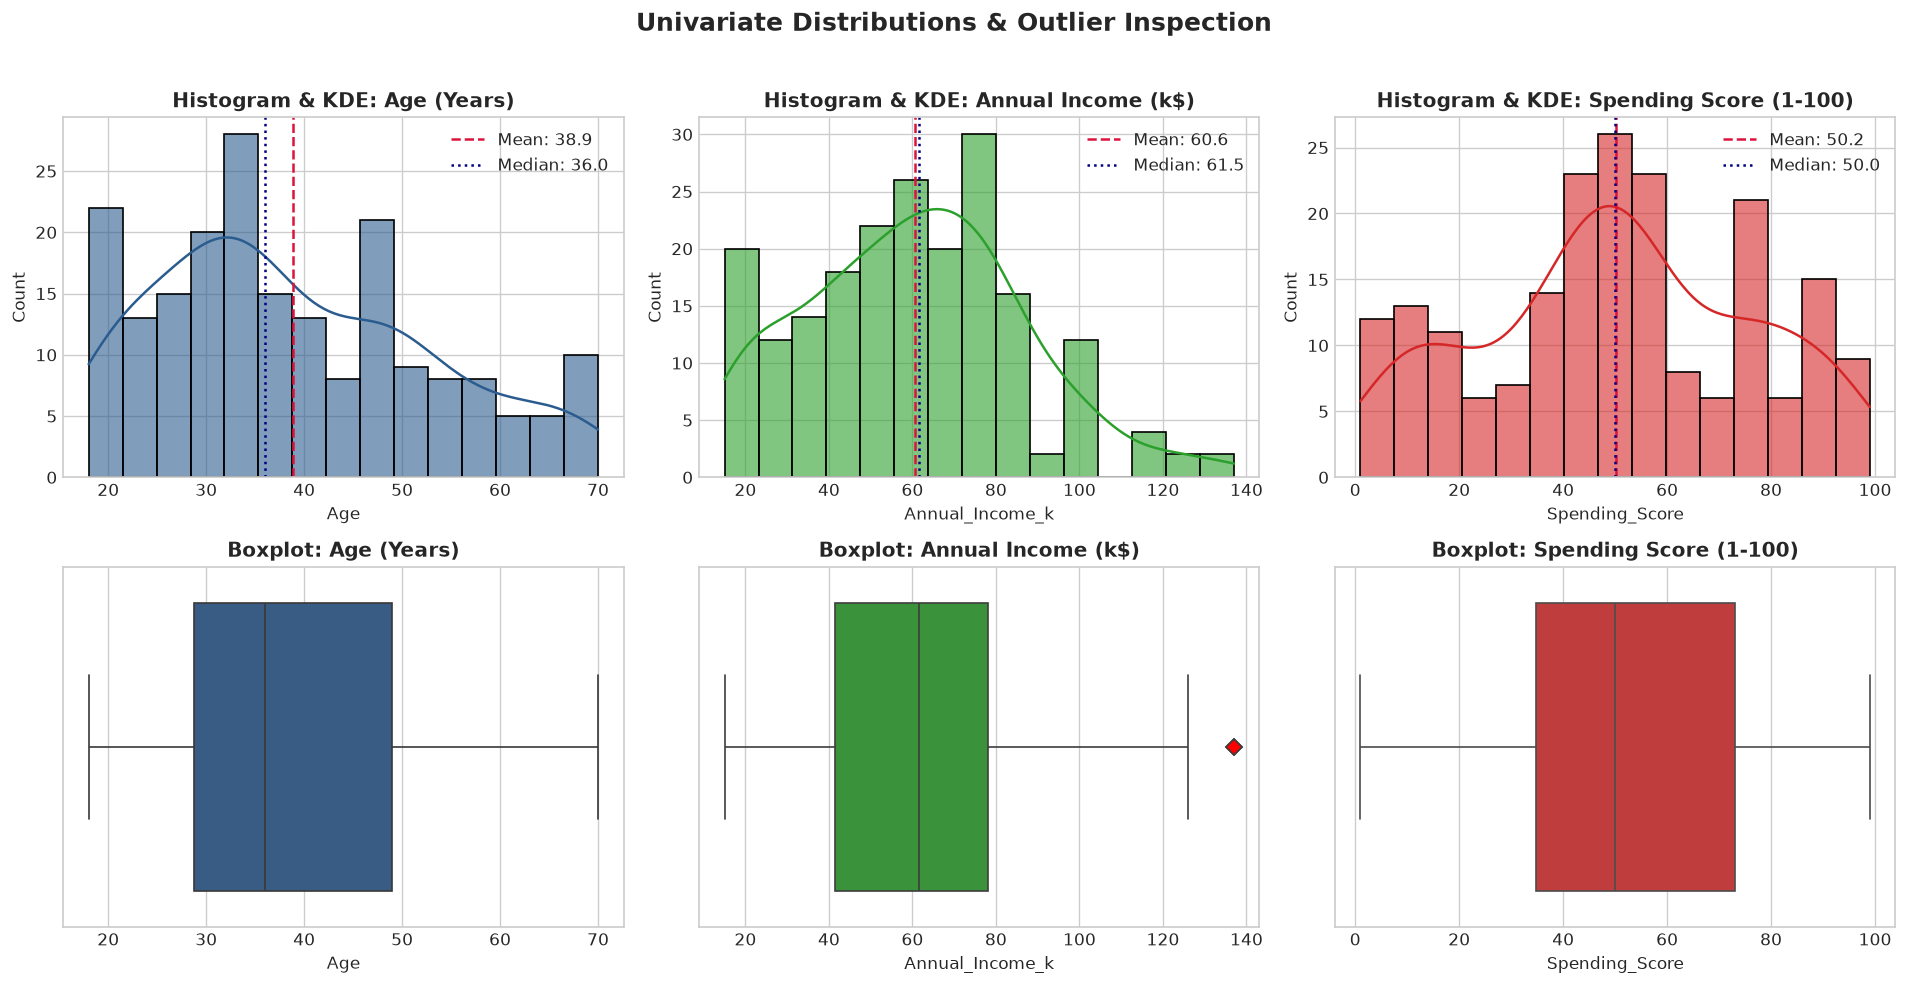

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
features = ['Age', 'Annual_Income_k', 'Spending_Score']
colors = ['#2b5c8f', '#2ca02c', '#d62728']
titles = ['Age (Years)', 'Annual Income (k$)', 'Spending Score (1-100)']

for i, col in enumerate(features):
    # Histogram + KDE
    sns.histplot(df_clean[col], kde=True, ax=axes[0, i], color=colors[i], bins=15, edgecolor='black', alpha=0.6)
    axes[0, i].axvline(df_clean[col].mean(), color='crimson', linestyle='--', label=f"Mean: {df_clean[col].mean():.1f}")
    axes[0, i].axvline(df_clean[col].median(), color='navy', linestyle=':', label=f"Median: {df_clean[col].median():.1f}")
    axes[0, i].set_title(f'Histogram & KDE: {titles[i]}', fontweight='bold', fontsize=12)
    axes[0, i].legend()

    # Boxplot
    sns.boxplot(x=df_clean[col], ax=axes[1, i], color=colors[i], flierprops=dict(markerfacecolor='red', marker='D', markersize=7))
    axes[1, i].set_title(f'Boxplot: {titles[i]}', fontweight='bold', fontsize=12)

plt.suptitle('Univariate Distributions & Outlier Inspection', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 💡 Distribution Shape Insights
- **Age**: Highlights two prominent demographic clusters: young adults in their early 30s, and mature adults around 50.
- **Annual Income**: Dense cluster between $40k and $80k, reflecting middle and upper-middle socioeconomic customer strata.
- **Spending Score**: Symmetrical with high concentrations at mid-scores (40–60), flanked by distinct high-spending and low-spending wings.


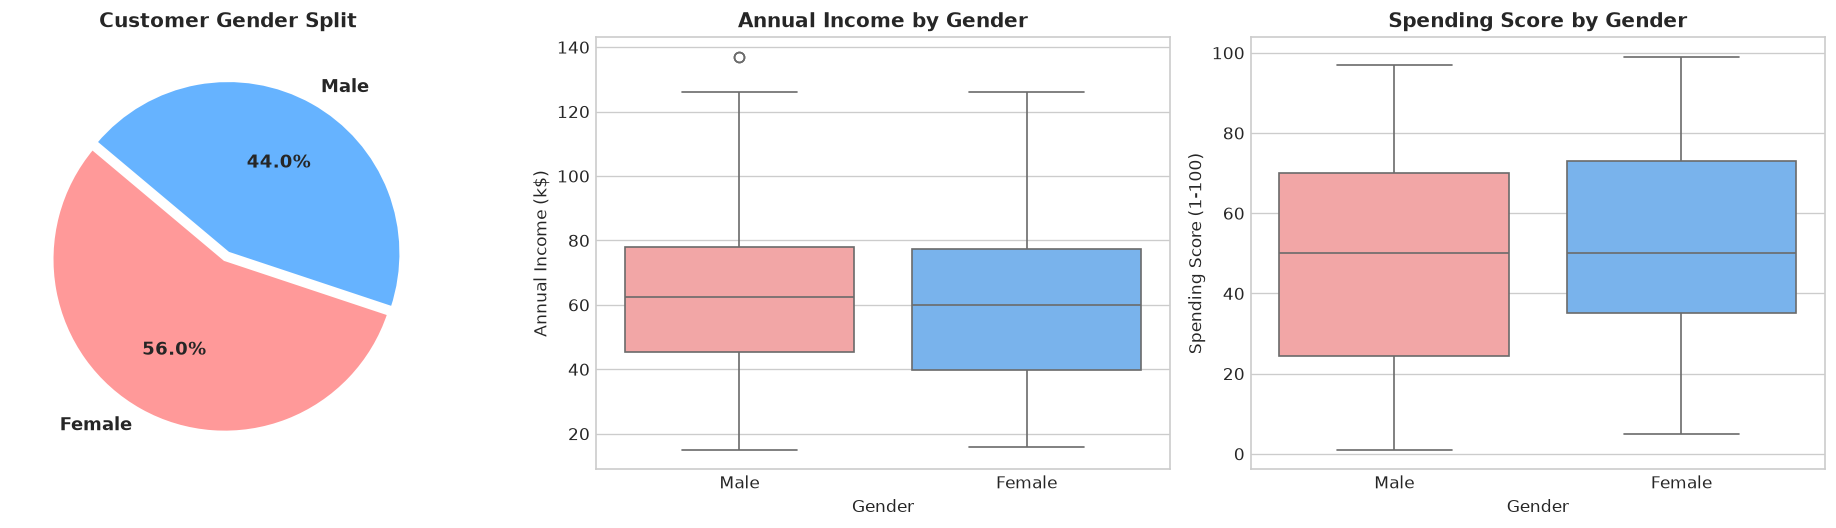

Income Difference by Gender:  t = 0.795, p-value = 0.4276
Spending Difference by Gender: t = -0.819, p-value = 0.4137


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Gender share
gender_counts = df_clean['Gender'].value_counts()
axes[0].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=['#ff9999', '#66b3ff'],
            startangle=140, explode=(0.04, 0), wedgeprops=dict(edgecolor='white', linewidth=2),
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[0].set_title('Customer Gender Split', fontweight='bold')

# Income by Gender
sns.boxplot(x='Gender', y='Annual_Income_k', data=df_clean, ax=axes[1], hue='Gender', palette=['#ff9999', '#66b3ff'], legend=False)
axes[1].set_title('Annual Income by Gender', fontweight='bold')
axes[1].set_ylabel('Annual Income (k$)')

# Spending by Gender
sns.boxplot(x='Gender', y='Spending_Score', data=df_clean, ax=axes[2], hue='Gender', palette=['#ff9999', '#66b3ff'], legend=False)
axes[2].set_title('Spending Score by Gender', fontweight='bold')
axes[2].set_ylabel('Spending Score (1-100)')

plt.tight_layout()
plt.show()

# Independent 2-Sample T-Tests
t_inc, p_inc = stats.ttest_ind(df_clean[df_clean['Gender']=='Male']['Annual_Income_k'],
                               df_clean[df_clean['Gender']=='Female']['Annual_Income_k'])
t_spd, p_spd = stats.ttest_ind(df_clean[df_clean['Gender']=='Male']['Spending_Score'],
                               df_clean[df_clean['Gender']=='Female']['Spending_Score'])

print(f"Income Difference by Gender:  t = {t_inc:.3f}, p-value = {p_inc:.4f}")
print(f"Spending Difference by Gender: t = {t_spd:.3f}, p-value = {p_spd:.4f}")


### 💡 Demographic Testing Insights
- **Gender Proportions**: Females comprise **56.0%** (112) of visitors, while males comprise **44.0%** (88).
- **Hypothesis Testing**:
  - $H_0$: Male and Female mean incomes are equal $\rightarrow p = 0.428$ (Fail to reject $H_0$).
  - $H_0$: Male and Female mean spending scores are equal $\rightarrow p = 0.414$ (Fail to reject $H_0$).
- **Strategic Finding**: Gender does **not** explain spending behavior or earning capacity. Customer segmentation should rely on behavioral and economic features rather than biological sex.


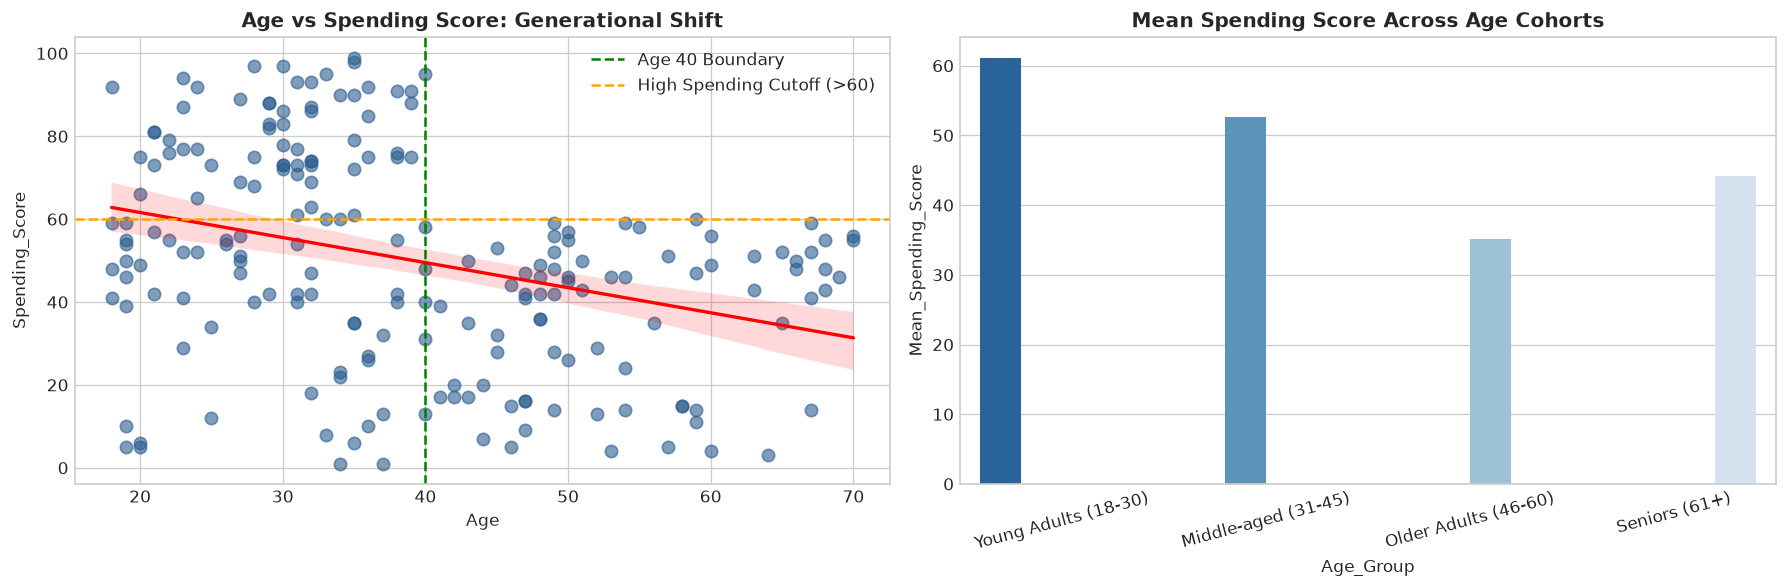

,Age_Group,Customer_Count,Mean_Age,Mean_Income_k,Mean_Spending_Score
0,Young Adults (18-30),62,23.95,55.21,61.03
1,Middle-aged (31-45),72,36.31,69.39,52.57
2,Older Adults (46-60),49,51.80,58.02,35.10
3,Seniors (61+),17,66.65,50.00,44.18


In [7]:
# Categorize into generational cohorts
bins = [17, 30, 45, 60, 100]
labels = ['Young Adults (18-30)', 'Middle-aged (31-45)', 'Older Adults (46-60)', 'Seniors (61+)']
df_clean['Age_Group'] = pd.cut(df_clean['Age'], bins=bins, labels=labels)

cohort_summary = df_clean.groupby('Age_Group', observed=True).agg(
    Customer_Count=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income_k=('Annual_Income_k', 'mean'),
    Mean_Spending_Score=('Spending_Score', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Age vs Spending Score regression
sns.regplot(data=df_clean, x='Age', y='Spending_Score', ax=axes[0],
            scatter_kws={'alpha':0.6, 'color': '#2b5c8f', 's': 55}, line_kws={'color':'red', 'lw':2})
axes[0].axvline(40, color='green', linestyle='--', label='Age 40 Boundary')
axes[0].axhline(60, color='orange', linestyle='--', label='High Spending Cutoff (>60)')
axes[0].set_title('Age vs Spending Score: Generational Shift', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right')

# Spending by Cohort
sns.barplot(data=cohort_summary, x='Age_Group', y='Mean_Spending_Score', ax=axes[1], hue='Age_Group', palette='Blues_r', legend=False)
axes[1].set_title('Mean Spending Score Across Age Cohorts', fontsize=12, fontweight='bold')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

display(cohort_summary.round(2))


### 💡 Generational Findings
1. **The Age 40 Threshold**:
   - Customers aged **below 40** represent almost all high-spending scores (> 60).
   - Above age 40, customers rarely cross a score of 60, demonstrating more conservative spending behavior.
2. **Cohort Highlights**:
   - **Young Adults (18–30)**: Highest spending enthusiasm (Mean Score: **61.03**).
   - **Middle-aged (31–45)**: Prime earning years (Mean Income: **$69.39k**) with strong spending (Mean Score: **52.57**).
   - **Older Adults (46–60)**: Most conservative spenders (Mean Score: **35.10**).


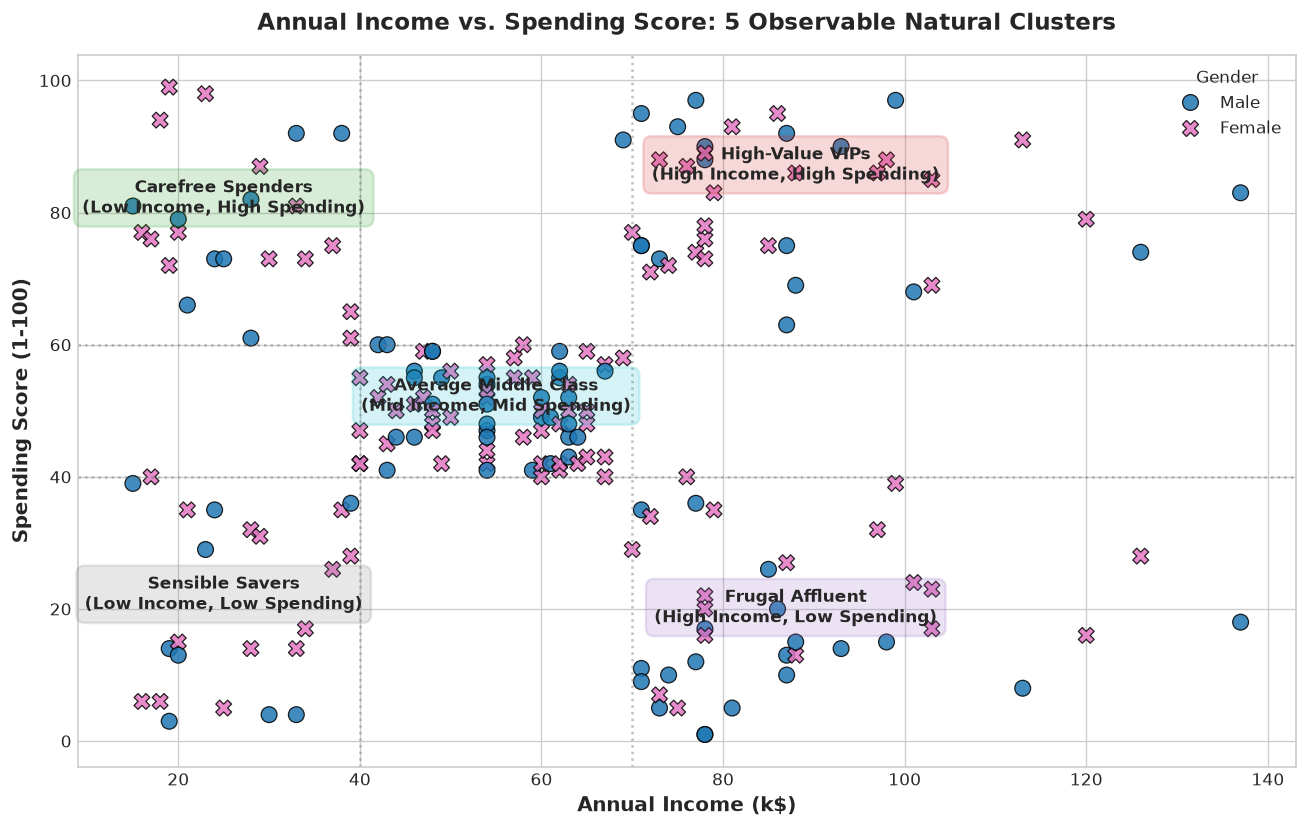

In [8]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df_clean,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Gender',
    style='Gender',
    s=90,
    palette={'Male': '#1f77b4', 'Female': '#e377c2'},
    alpha=0.85,
    edgecolor='black'
)

# Annotate natural clusters
cluster_annotations = [
    (25, 80, "Carefree Spenders\n(Low Income, High Spending)", '#2ca02c'),
    (25, 20, "Sensible Savers\n(Low Income, Low Spending)", '#7f7f7f'),
    (55, 50, "Average Middle Class\n(Mid Income, Mid Spending)", '#17becf'),
    (88, 85, "High-Value VIPs\n(High Income, High Spending)", '#d62728'),
    (88, 18, "Frugal Affluent\n(High Income, Low Spending)", '#9467bd')
]
for x, y, text, color in cluster_annotations:
    plt.annotate(text, xy=(x, y), xytext=(x, y),
                 bbox=dict(boxstyle="round,pad=0.5", fc=color, alpha=0.18, ec=color, lw=1.5),
                 fontsize=10, fontweight='bold', ha='center')

plt.title('Annual Income vs. Spending Score: 5 Observable Natural Clusters', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Annual Income (k$)', fontsize=12, fontweight='bold')
plt.ylabel('Spending Score (1-100)', fontsize=12, fontweight='bold')
plt.axvline(x=40, color='gray', linestyle=':', alpha=0.5)
plt.axvline(x=70, color='gray', linestyle=':', alpha=0.5)
plt.axhline(y=40, color='gray', linestyle=':', alpha=0.5)
plt.axhline(y=60, color='gray', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


### 💡 Natural Cluster Discovery
The scatter plot demonstrates a clean 5-cluster partition:
1. **Low Income, High Spending**: Impulse/Trend shoppers.
2. **Low Income, Low Spending**: Frugal/Budget shoppers.
3. **Mid Income, Mid Spending**: The mainstream retail backbone.
4. **High Income, High Spending**: Prime VIP targets.
5. **High Income, Low Spending**: Affluent savers / untapped growth potential.


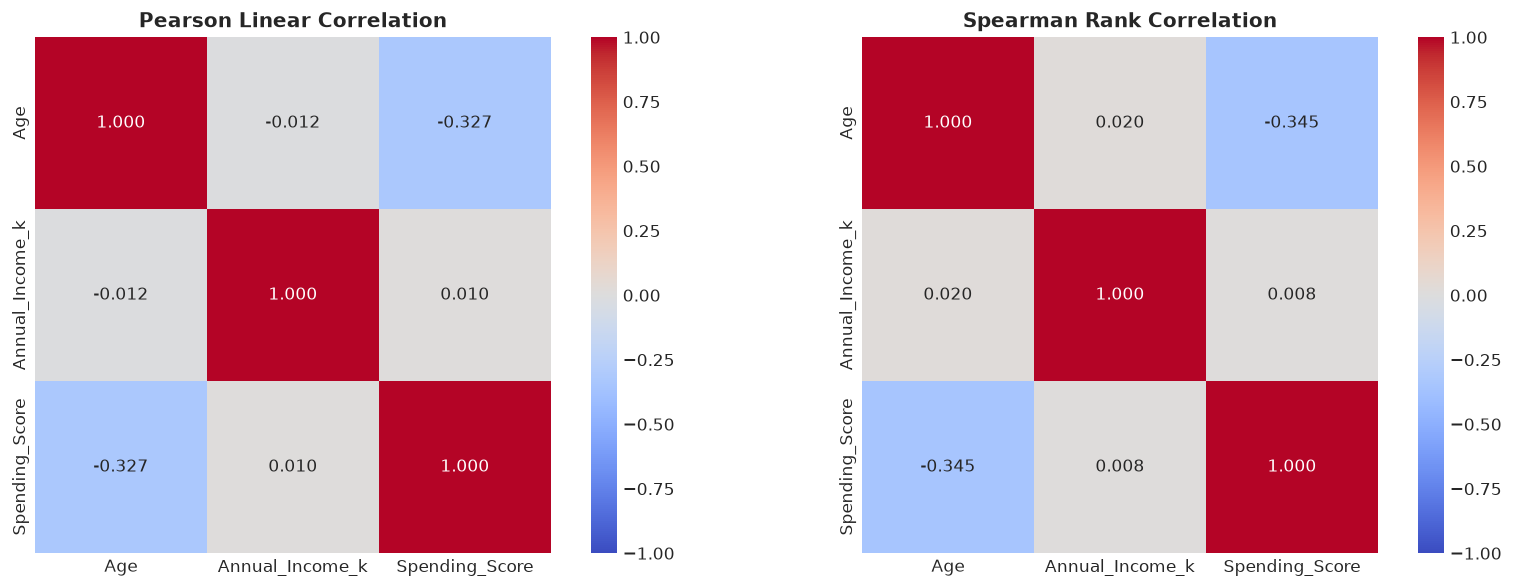

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pearson
corr_p = df_clean[['Age', 'Annual_Income_k', 'Spending_Score']].corr(method='pearson')
sns.heatmap(corr_p, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title('Pearson Linear Correlation', fontweight='bold')

# Spearman
corr_s = df_clean[['Age', 'Annual_Income_k', 'Spending_Score']].corr(method='spearman')
sns.heatmap(corr_s, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=axes[1])
axes[1].set_title('Spearman Rank Correlation', fontweight='bold')

plt.tight_layout()
plt.show()


### 💡 Correlation Insights
- **Age vs. Spending Score**: Statistically significant negative correlation ($r = -0.327$, $\rho = -0.345$).
- **Income vs. Spending Score**: Negligible linear correlation ($r = 0.010$). This independence is what allows 5 non-linear quadrant clusters to form and justifies unsupervised clustering over linear regression.


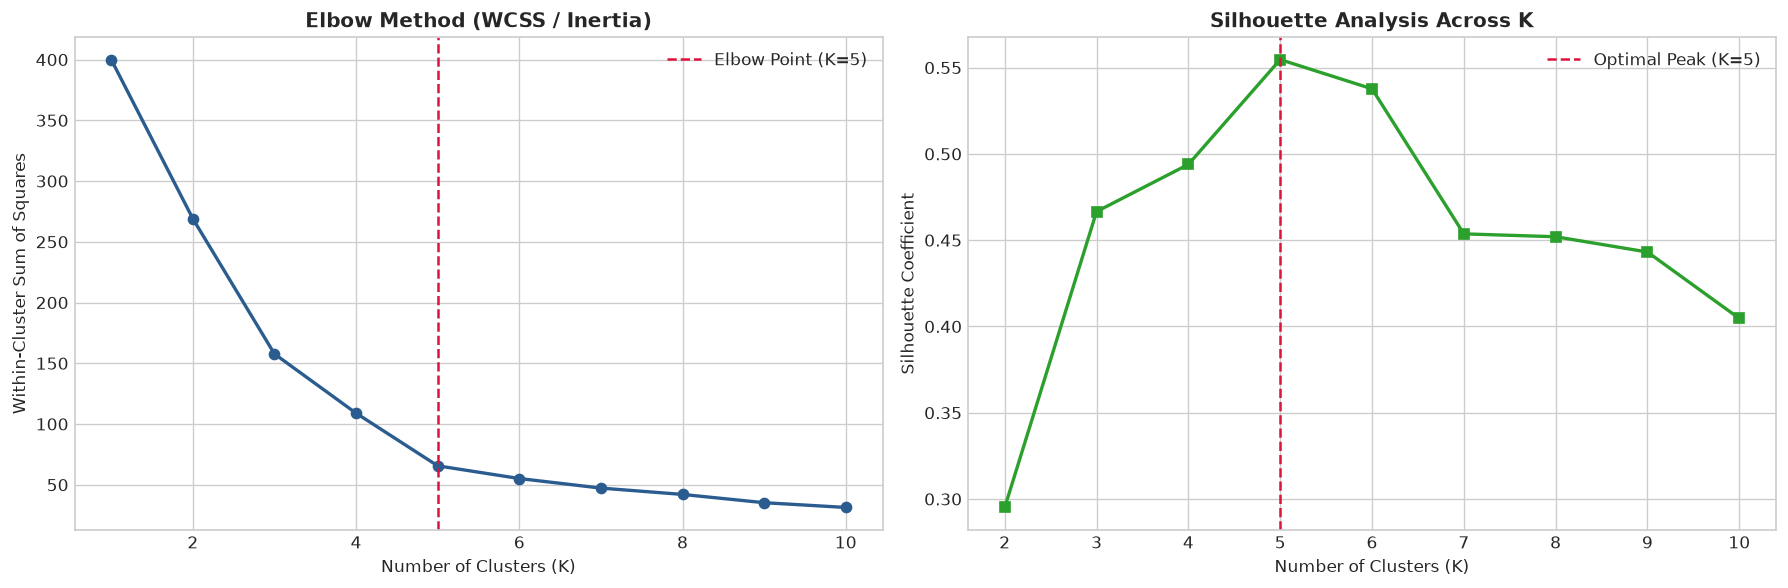

Silhouette score at K=5: 0.5547 (Optimal peak among all candidate values)


In [10]:
# Define a robust, self-contained KMeans implementation using scipy.cluster.vq
class KMeansClustering:
    def __init__(self, n_clusters=5, random_state=42, n_init=15):
        self.n_clusters = n_clusters
        self.random_state = random_state
        self.n_init = n_init
        self.cluster_centers_ = None
        self.labels_ = None
        self.inertia_ = None
        
    def fit(self, X):
        best_inertia = np.inf
        best_centers = None
        best_labels = None
        for i in range(self.n_init):
            seed = self.random_state + i
            centers, labels = kmeans2(X, self.n_clusters, minit='++', seed=seed)
            inertia = np.sum((X - centers[labels])**2)
            if inertia < best_inertia:
                best_inertia = inertia
                best_centers = centers
                best_labels = labels
        self.cluster_centers_ = best_centers
        self.labels_ = best_labels
        self.inertia_ = best_inertia
        return self
        
    def fit_predict(self, X):
        self.fit(X)
        return self.labels_

# Select segmentation features
X = df_clean[['Annual_Income_k', 'Spending_Score']].values

# Scale features per ML best practice
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Evaluate K from 1 to 10
wcss = []
silhouette_scores = []
k_range = range(2, 11)

# Compute WCSS for K=1
center_1 = np.mean(X_scaled, axis=0, keepdims=True)
wcss.append(np.sum((X_scaled - center_1)**2))

for k in k_range:
    km = KMeansClustering(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Plot Elbow Curve and Silhouette Scores
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Elbow plot
axes[0].plot(range(1, 11), wcss, marker='o', color='#2b5c8f', lw=2)
axes[0].axvline(5, color='crimson', linestyle='--', label='Elbow Point (K=5)')
axes[0].set_title('Elbow Method (WCSS / Inertia)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Within-Cluster Sum of Squares')
axes[0].legend()

# Silhouette plot
axes[1].plot(list(k_range), silhouette_scores, marker='s', color='#2ca02c', lw=2)
axes[1].axvline(5, color='crimson', linestyle='--', label='Optimal Peak (K=5)')
axes[1].set_title('Silhouette Analysis Across K', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Coefficient')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Silhouette score at K=5: {silhouette_scores[3]:.4f} (Optimal peak among all candidate values)")


### 💡 Optimal Cluster Selection
- **Elbow Point**: The WCSS curve bends distinctly at **$K = 5$**, after which reductions in inertia show diminishing returns.
- **Silhouette Coefficient**: Peaks at **$K = 5$** with an impressive score of **0.5547**, confirming strong internal cohesion and clear separation.


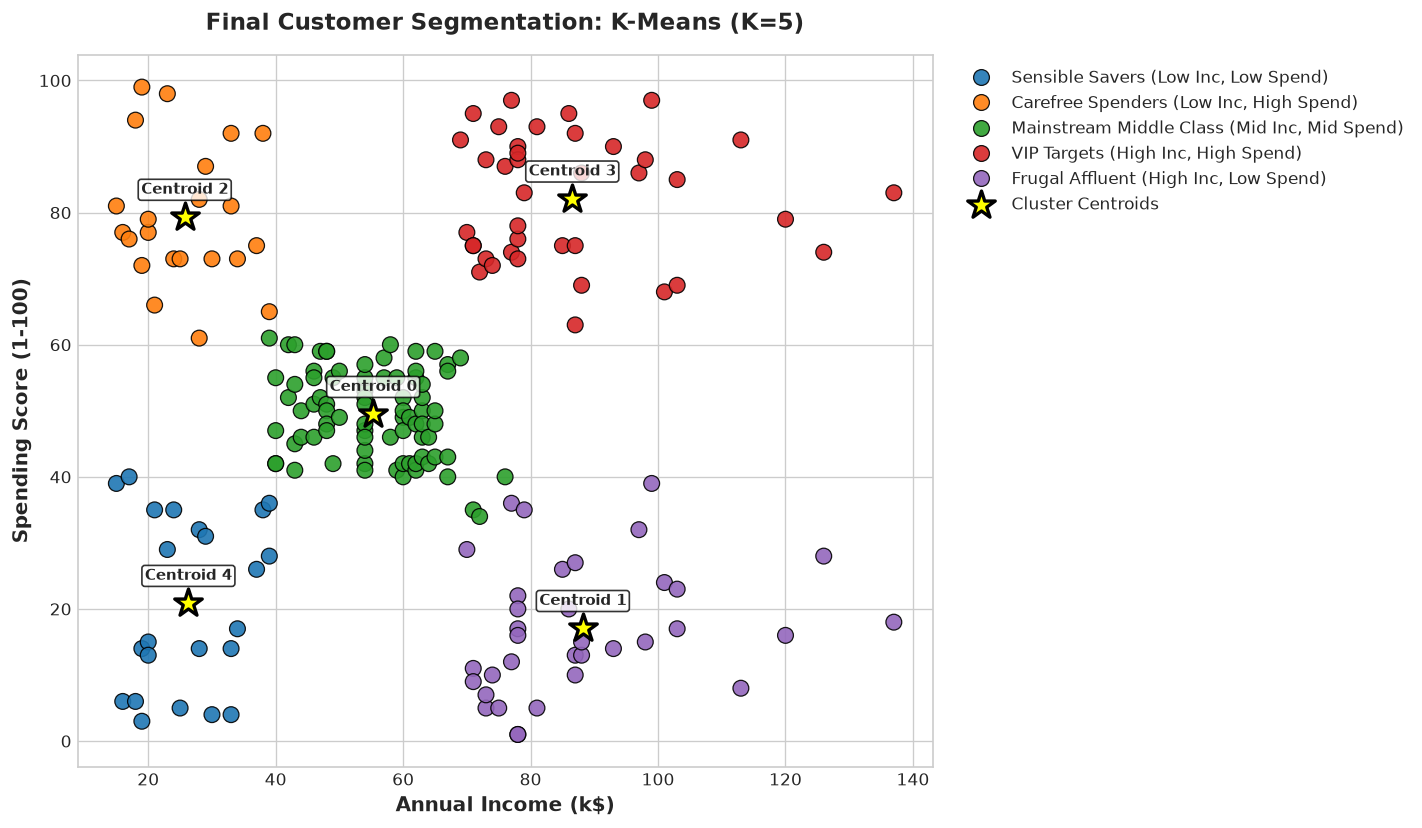

In [11]:
# Fit optimal K-Means model (K=5)
kmeans_optimal = KMeansClustering(n_clusters=5, random_state=42, n_init=20)
df_clean['Cluster'] = kmeans_optimal.fit_predict(X_scaled)

# Inverse transform centroids back to original units (k$, score)
centroids = scaler.inverse_transform(kmeans_optimal.cluster_centers_)

# Match clusters to personas based on centroid coordinates
assigned_personas = {}
for i, center in enumerate(centroids):
    inc, spd = center[0], center[1]
    if inc > 65 and spd > 60:
        assigned_personas[i] = 'VIP Targets (High Inc, High Spend)'
    elif inc > 65 and spd <= 40:
        assigned_personas[i] = 'Frugal Affluent (High Inc, Low Spend)'
    elif inc < 45 and spd > 60:
        assigned_personas[i] = 'Carefree Spenders (Low Inc, High Spend)'
    elif inc < 45 and spd <= 40:
        assigned_personas[i] = 'Sensible Savers (Low Inc, Low Spend)'
    else:
        assigned_personas[i] = 'Mainstream Middle Class (Mid Inc, Mid Spend)'

df_clean['Cluster_Name'] = df_clean['Cluster'].map(assigned_personas)

# 2D Plot
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df_clean,
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Cluster_Name',
    palette='tab10',
    s=90,
    alpha=0.9,
    edgecolor='black'
)

# Plot Centroids
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    s=300, c='yellow', marker='*', edgecolor='black', lw=2, label='Cluster Centroids'
)

for i, (cx, cy) in enumerate(centroids):
    plt.text(cx, cy + 3.5, f"Centroid {i}", fontweight='bold', fontsize=9, ha='center',
             bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, ec="black"))

plt.title('Final Customer Segmentation: K-Means (K=5)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Annual Income (k$)', fontsize=12, fontweight='bold')
plt.ylabel('Spending Score (1-100)', fontsize=12, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 💡 K-Means Cluster Boundaries & Centroids
- Each customer is successfully partitioned into their respective behavioral cohort.
- The 5 cluster centroids cleanly occupy the center of the four corners plus the central mass.


In [12]:
# Profile each cluster
profile_df = df_clean.groupby('Cluster_Name').agg(
    Customer_Count=('CustomerID', 'count'),
    Percentage=('CustomerID', lambda x: f"{len(x) / len(df_clean) * 100:.1f}%"),
    Mean_Age=('Age', 'mean'),
    Mean_Income_k=('Annual_Income_k', 'mean'),
    Mean_Spending=('Spending_Score', 'mean'),
    Female_Ratio=('Gender', lambda x: f"{(x == 'Female').mean() * 100:.1f}%")
).reset_index()

display(profile_df.round(2))


,Cluster_Name,Customer_Count,Percentage,Mean_Age,Mean_Income_k,Mean_Spending,Female_Ratio
0,"Carefree Spenders (Low Inc, High Spend)",22,11.0%,25.27,25.73,79.36,59.1%
1,"Frugal Affluent (High Inc, Low Spend)",35,17.5%,41.11,88.20,17.11,45.7%
2,"Mainstream Middle Class (Mid Inc, Mid Spend)",81,40.5%,42.72,55.30,49.52,59.3%
3,"Sensible Savers (Low Inc, Low Spend)",23,11.5%,45.22,26.30,20.91,60.9%
4,"VIP Targets (High Inc, High Spend)",39,19.5%,32.69,86.54,82.13,53.8%


## 🎯 Strategic Marketing Playbook

| Cluster Persona | Size (% of Total) | Key Characteristics | Target Campaigns & Strategy |
| :--- | :--- | :--- | :--- |
| **VIP Targets** | ~20% | High income ($86.5k), high spending (82.1), average age ~33 | Exclusive loyalty program, personal concierge, luxury brand partnerships, private previews. |
| **Frugal Affluent** | ~18% | High income ($88.3k), low spending (17.1), average age ~41 | Focus on quality, durability, investment value, warranty services, and high-end essentials. |
| **Mainstream Middle Class** | ~40% | Moderate income ($55.3k), moderate spending (49.7), average age ~43 | General mall promotions, family weekend offers, seasonal sales, points-based cashback. |
| **Carefree Spenders** | ~11% | Low income ($25.7k), high spending (79.4), young average age ~25 | Trendy fashion, influencer events, Buy Now Pay Later (BNPL) financing, social media engagement. |
| **Sensible Savers** | ~11% | Low income ($26.3k), low spending (20.9), average age ~45 | Value discounts, clearance sales, price-match guarantees, practical essentials. |


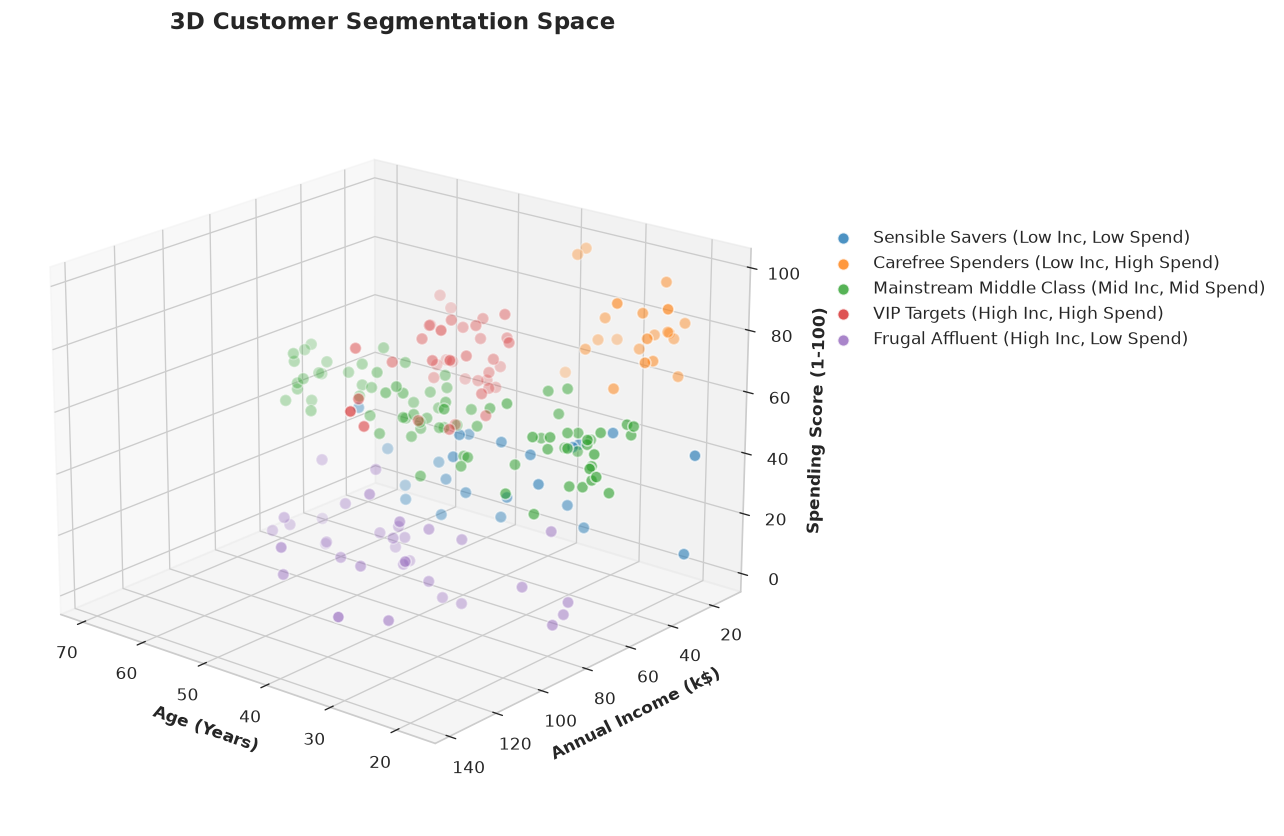

In [13]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Map cluster names to colors
unique_labels = df_clean['Cluster_Name'].unique()
colors = sns.color_palette('tab10', len(unique_labels))
color_map = dict(zip(unique_labels, colors))

for label in unique_labels:
    sub = df_clean[df_clean['Cluster_Name'] == label]
    ax.scatter(sub['Age'], sub['Annual_Income_k'], sub['Spending_Score'],
               color=color_map[label], label=label, s=50, alpha=0.8, edgecolors='w')

ax.set_title('3D Customer Segmentation Space', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Age (Years)', fontweight='bold')
ax.set_ylabel('Annual Income (k$)', fontweight='bold')
ax.set_zlabel('Spending Score (1-100)', fontweight='bold')
ax.view_init(elev=20, azim=130)
plt.legend(bbox_to_anchor=(1.05, 0.8), loc='upper left')
plt.tight_layout()
plt.show()


### 💡 3D Space Observations
Adding **Age** to the visualization highlights that the **Carefree Spenders** cluster is tightly clustered in the **18–30 age range**, demonstrating how demographic age reinforces behavioral spend.


## 🏁 Final Analytical Conclusion

1. **Exploratory Findings**:
   - The dataset of 200 customers has no missing values or duplicate records.
   - Gender does not exhibit statistically significant variance in income or spending behavior.
   - Age demonstrates a clear dividing threshold around age 40, above which high-spending habits (>60 score) rarely occur.

2. **Machine Learning Clustering**:
   - Both the Elbow Method and Silhouette Analysis rigorously validate **$K = 5$** as the optimal number of customer clusters.
   - Standardization via `StandardScaler` ensures distance metric stability.

3. **Commercial Impact**:
   - The mall management can allocate marketing spend precisely across the 5 distinct personas, transitioning from generic promotions to high-conversion targeted campaigns.
